In [ ]:
import numpy as np
import matplotlib.pyplot as plt
logs = [
    '/data/models/bin/2026_pathway_generation/reference_logs/resnet18_20260203_210148/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_20260203_210225/'
]
labels = ['resnet18','swin']

resnet18: Train Min: 1.2048. Val Min: 1.2952
resnet50: Train Min: 0.86. Val Min: 1.2619
convnext: Train Min: 0.6154. Val Min: 1.2368
swin: Train Min: 0.802. Val Min: 1.1511
vit: Train Min: 0.7928. Val Min: 1.3118


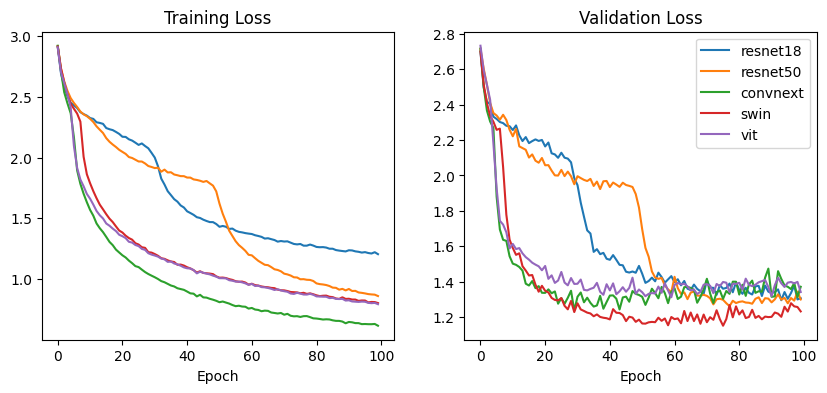

In [9]:
fig, axs = plt.subplots(1,2, figsize=(10,4))
for i, log in enumerate(logs):
    loss = np.load(log+'loss_log.pkl', allow_pickle=True)
    train = np.stack(loss['train'])
    val = np.stack(loss['val'])
    count = int(len(train)/330)
    train = np.stack([np.mean(train[i*330:(i+1)*330]) for i in range(count)])
    print(f"{labels[i]}: Train Min: {round(train.min(),4)}. Val Min: {round(val.min(), 4)}")
    axs[0].plot(train, label=labels[i])
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[1].plot(val, label=labels[i])
    axs[1].set_title('Validation Loss')
    axs[1].set_xlabel('Epoch')
    plt.legend()
pass